# Память и обработка частями в Pandas

На 200 000 синтетических заказов рассматриваются чтение нужных колонок, типы данных, измерение памяти и обработка CSV частями. Все ячейки заранее выполнены; рядом с методом виден его результат. Исходный orders.csv читается, но никогда не изменяется.

Суммы заказов записаны целыми единицами. Поэтому для денег используются точные целые значения и достаточно широкий тип для общих сумм. Снижение памяти не должно менять арифметику. Сравнение скорости на одном запуске остаётся лишь наблюдением на данной машине.

В конце строится прозрачный конвейер чанков с проверками входа и журналом диагностики. Его артефакты будут лежать только в собственной папке модуля.

## Типы и память

Измеряется исходное представление, повторяющиеся строки переводятся в category с сохранением точности целых сумм.

**Прочитать исходную таблицу**

Сначала выполняется чтение CSV, затем проверяются форма, типы и первые записи. Этот полный DataFrame нужен как эталон для последующих сравнений, а не как обязательный шаг любого промышленного конвейера. Путь определяется по точному data/orders.csv в рабочем каталоге и его родителях. Файл остаётся неизменным. Автоматический вывод типов удобен, но не является контрактом: строки становятся object, дата может остаться текстом. На этой стадии важно узнать, что действительно прочитано, прежде чем обещать экономию памяти или правильные временные операции. Данные содержат 200 000 синтетических заказов.

In [1]:
# Шаг 04.01 — Прочитать исходную таблицу
from pathlib import Path
from datetime import datetime, timedelta
import logging
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
get_ipython().run_line_magic('matplotlib', 'inline')

data_dir = next((p / 'data' for p in (Path.cwd(), *Path.cwd().parents)
                 if (p / 'data' / 'orders.csv').is_file()), None)
if data_dir is None:
    raise FileNotFoundError('Нужен data/orders.csv')
source = data_dir / 'orders.csv'
full = pd.read_csv(source)
print('Строк и колонок:', full.shape)
display(full.head())
display(full.dtypes.to_frame('выведенный тип'))

Строк и колонок: (200000, 10)


,order_id,order_ts,customer_id,city,product_id,category,qty,price,amount,status
0,1,2026-01-17 08:50:04,8384,Санкт-Петербург,1104,Одежда,1,9700,9700,delivered
1,2,2026-07-13 14:51:05,11971,Краснодар,1471,Продукты,1,480,480,delivered
2,3,2026-11-03 13:42:32,19274,Новосибирск,887,Обувь,1,7630,7630,delivered
3,4,2026-03-19 16:38:33,14821,Москва,79,Одежда,1,11660,11660,returned
4,5,2026-11-27 01:54:49,6548,Москва,1397,Бытовая техника,1,57730,57730,delivered


,выведенный тип
order_id,int64
order_ts,object
customer_id,int64
city,object
product_id,int64
category,object
qty,int64
price,int64
amount,int64
status,object


**Измерить память по колонкам**

Функция memory_usage с deep=True учитывает глубже содержимое строковых object-колонок. Без этого параметра оценка может заметно занизить стоимость текста, поскольку учитывает в основном ссылки. Выводятся расход по колонкам и общая сумма в мегабайтах. Это память DataFrame, а не полное потребление процесса Python: интерпретатор, временные объекты и загруженные библиотеки тоже занимают место. Число нужно читать как сравнимую оценку конкретного представления таблицы. После задания явных типов используется тот же способ измерения. Контроль по колонкам подсказывает, на что воздействовать в первую очередь.

In [2]:
# Шаг 04.02 — Измерить память по колонкам
memory_before = full.memory_usage(deep=True)
print('Всего МиБ:', memory_before.sum() / 2**20)
display((memory_before / 2**20).sort_values(ascending=False).to_frame('МиБ'))

Всего МиБ: 64.61926555633545


,МиБ
city,15.745949
category,15.687357
order_ts,12.969971
status,11.060590
order_id,1.525879
product_id,1.525879
customer_id,1.525879
price,1.525879
qty,1.525879
amount,1.525879


**Задать схему при чтении**

read_csv умеет выбрать только нужные колонки через usecols, назначить типы через dtype и сразу разобрать дату через parse_dates. Для демонстрации остаются поля, нужные дальнейшим расчётам, а идентификатор товара исключается. Явная схема делает намерение видимым и уменьшает случайные преобразования после загрузки. Для amount заранее сохраняется int64: сумма всех строк намного больше диапазона малого целого, даже если каждая отдельная покупка невелика. Строковые поля пока сохраняются как string; выбор category рассматривается отдельно. Если вход нарушит заявленную схему, чтение должно сообщить об этом, а не скрыть проблему.

In [3]:
# Шаг 04.03 — Задать схему при чтении
columns = ['order_id', 'order_ts', 'customer_id', 'city', 'category', 'qty', 'price', 'amount', 'status']
schema = {'order_id': 'int64', 'customer_id': 'int32', 'city': 'string',
          'category': 'string', 'qty': 'int16', 'price': 'int32',
          'amount': 'int64', 'status': 'string'}
typed = pd.read_csv(source, usecols=columns, dtype=schema, parse_dates=['order_ts'])
print('Колонок:', len(typed.columns), 'строк:', len(typed))
display(typed.dtypes.to_frame('явный тип'))
display(typed.head(3))

Колонок: 9 строк: 200000


,явный тип
order_id,int64
order_ts,datetime64[ns]
customer_id,int32
city,string[python]
category,string[python]
qty,int16
price,int32
amount,int64
status,string[python]


,order_id,order_ts,customer_id,city,category,qty,price,amount,status
0,1,2026-01-17 08:50:04,8384,Санкт-Петербург,Одежда,1,9700,9700,delivered
1,2,2026-07-13 14:51:05,11971,Краснодар,Продукты,1,480,480,delivered
2,3,2026-11-03 13:42:32,19274,Новосибирск,Обувь,1,7630,7630,delivered


**Проверить повторяемость строк**

Категориальный тип особенно полезен для строк с небольшим числом повторяющихся значений. Подсчитывается число различных городов, категорий товаров и статусов относительно количества строк. Уникальные идентификаторы таким способом обычно экономятся хуже: словарь категорий почти столь же велик, как столбец. Число уникальных значений само по себе не доказывает экономию, поэтому далее сравнивается память до и после преобразования. Смысл столбцов не меняется: category хранит коды и таблицу значений, а при отображении видны прежние строки. Такой тип может влиять на поведение операций, поэтому его применяют избирательно.

In [4]:
# Шаг 04.04 — Проверить повторяемость строк
repeat_columns = ['city', 'category', 'status']
distinct = typed[repeat_columns].nunique().rename('различных')
display(pd.DataFrame({'различных': distinct, 'строк': len(typed),
                      'доля_различных': distinct / len(typed)}))

,различных,строк,доля_различных
city,16,200000,0.000080
category,9,200000,0.000045
status,4,200000,0.000020


**Перевести повторяющиеся строки в category**

Создаётся копия явной таблицы; только три повторяющихся строковых столбца переводятся в category. После этого сравниваются глубокая память с исходным string-представлением и равенство значений. Преобразование не должно менять город, категорию товара или статус заказа. Экономия зависит от числа повторов и внутреннего представления Pandas; её следует измерять на собственных данных. Категориальный тип полезен для группировки по небольшой известной шкале, но динамически меняющийся словарь новых значений требует внимания при объединении наборов. Здесь учебный набор статичен.

In [5]:
# Шаг 04.05 — Перевести повторяющиеся строки в category
compact = typed.copy()
for col in repeat_columns:
    compact[col] = compact[col].astype('category')
    assert compact[col].astype('string').equals(typed[col])
comparison = pd.DataFrame({
    'string_МиБ': typed[repeat_columns].memory_usage(deep=True).drop('Index') / 2**20,
    'category_МиБ': compact[repeat_columns].memory_usage(deep=True).drop('Index') / 2**20,
})
display(comparison)

,string_МиБ,category_МиБ
city,19.060119,0.192810
category,18.935607,0.191864
status,11.060590,0.191120


**Выбрать диапазоны целых типов**

Перед downcast проверяются минимумы и максимумы каждого числового поля. Для идентификаторов, количества и цены можно выбрать меньший беззнаковый тип, если все значения неотрицательны и входят в его диапазон. При этом для общего amount сохраняется int64: отдельное значение меньше миллиона, а сумма всего набора превышает границу int32. Тип отдельной строки и тип агрегата — разные решения. Здесь деньги представлены целыми единицами, поэтому точность сохраняется без float. Если в реальном наборе деньги записаны с копейками, сначала нужна явная модель единиц или decimal, а не неявное округление.

In [6]:
# Шаг 04.06 — Выбрать диапазоны целых типов
numeric = ['order_id', 'customer_id', 'qty', 'price', 'amount']
ranges = typed[numeric].agg(['min', 'max'])
display(ranges)
small = compact.copy()
for col in ['order_id', 'customer_id', 'qty', 'price']:
    small[col] = pd.to_numeric(small[col], downcast='unsigned')
    assert np.array_equal(small[col].to_numpy(), compact[col].to_numpy())
display(small[numeric].dtypes.to_frame('тип после downcast'))

,order_id,customer_id,qty,price,amount
min,1,1,1,90,90
max,200000,20000,5,119880,599400


,тип после downcast
order_id,uint32
customer_id,uint16
qty,uint8
price,uint32
amount,int64


**Проверить точность итогов**

Снижение памяти имеет смысл только при сохранении аналитического результата. Проверяется равенство построчного amount произведению qty и price, а также равенство общей и доставленной сумм до и после оптимизации. Все эти суммы рассчитываются в int64. Для денежных целых значений здесь уместно точное равенство, а не допуск для float. Контроль охватывает и строки, и итоговые агрегаты: совпадение одной общей суммы могло бы скрыть взаимно компенсирующиеся ошибки. В нашем синтетическом файле доставленная сумма известна как контрольный ориентир, но источник истины всё равно сам набор данных.

In [7]:
# Шаг 04.07 — Проверить точность итогов
assert (small['amount'].astype('int64') ==
        small['qty'].astype('int64') * small['price'].astype('int64')).all()
full_sum = int(typed['amount'].sum())
small_sum = int(small['amount'].astype('int64').sum())
delivered_sum = int(small.loc[small['status'].eq('delivered'), 'amount'].astype('int64').sum())
assert full_sum == small_sum
assert delivered_sum == 5_135_476_730
print('Все заказы:', full_sum, 'доставленные:', delivered_sum)

Все заказы: 6266419540 доставленные: 5135476730


**Сравнить общий расход памяти**

Полный расход явной и оптимизированной таблиц измеряется одним и тем же методом memory_usage(deep=True). Разница отражает эффект выбранных колонок и типов для этих 200 000 строк, но не гарантирует такую же экономию на другом наборе. Наглядная столбчатая диаграмма показывает относительный масштаб. Диаграмма сохраняется в outputs модуля для визуальной проверки. Расход оперативной памяти процесса может быть больше из-за временных копий, работы интерпретатора и рисунка. Поэтому показатель следует применять как локальную метрику представления DataFrame, а не как точный бюджет запуска.

,МиБ
явные типы,55.541427
category и downcast,5.725761


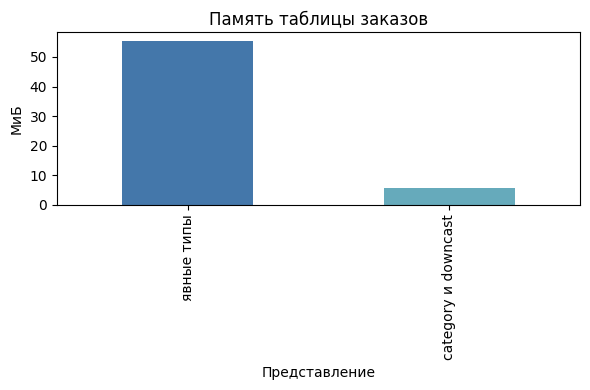

In [8]:
# Шаг 04.08 — Сравнить общий расход памяти
mem_table = pd.Series({'явные типы': typed.memory_usage(deep=True).sum() / 2**20,
                       'category и downcast': small.memory_usage(deep=True).sum() / 2**20})
display(mem_table.to_frame('МиБ'))
plot_dir = Path.cwd() / 'outputs'
plot_dir.mkdir(exist_ok=True)
fig, ax = plt.subplots(figsize=(6, 4))
mem_table.plot.bar(ax=ax, color=['#4477aa', '#66aabb'])
ax.set(title='Память таблицы заказов', xlabel='Представление', ylabel='МиБ')
fig.tight_layout()
fig.savefig(plot_dir / '04_память.png', dpi=130)
plt.show()
plt.close(fig)

Оптимизация памяти считается успешной только вместе с проверкой исходных значений и итоговых сумм.

## Вычисления и чанки

Сравниваются векторное выражение и построчная функция; далее разбираются аддитивные агрегаты чанков.

**Вычислить выражение векторно**

Векторные операции Pandas выполняют арифметику над целыми столбцами без явной функции Python на каждую строку. На умеренной выборке вычисляется произведение qty и price. Результат сравнивается с amount, чтобы измерение скорости не сравнивало разные вычисления. Новая бизнес-логика здесь не создаётся: формула уже задана схемой синтетических заказов. Для больших данных векторность часто полезна, но она может временно выделить промежуточные массивы. Поэтому скорость и память нужно оценивать отдельно, а не заменять одно слово «оптимизация» другим.

In [9]:
# Шаг 04.09 — Вычислить выражение векторно
sample = small.head(20_000).copy()
vector_amount = sample['qty'].astype('int64') * sample['price'].astype('int64')
assert np.array_equal(vector_amount.to_numpy(), sample['amount'].to_numpy())
print('Строк образца:', len(sample), 'сумма:', int(vector_amount.sum()))

Строк образца: 20000 сумма: 625788380


**Сравнить apply на образце**

Построчный apply вызывает функцию Python для каждой строки и поэтому часто уступает векторному выражению. Оба способа измеряются на одном умеренном образце после проверки идентичности значений. Один запуск perf_counter показывает лишь результат данной машины, текущей нагрузки и размеров образца. Он не гарантирует постоянное ускорение в продакшене; для серьёзного выбора нужны повторные измерения и контроль окружения. Здесь цель — увидеть цену построчной функции и не путать её с точностью вычисления. Для учебного тезиса не требуется большой многократный бенчмарк.

In [10]:
# Шаг 04.10 — Сравнить apply на образце
t0 = time.perf_counter()
vector_check = sample['qty'].astype('int64') * sample['price'].astype('int64')
vector_seconds = time.perf_counter() - t0
t0 = time.perf_counter()
apply_check = sample.apply(lambda row: int(row['qty']) * int(row['price']), axis=1)
apply_seconds = time.perf_counter() - t0
assert np.array_equal(vector_check.to_numpy(), apply_check.to_numpy())
print({'векторно_с': round(vector_seconds, 4), 'apply_с': round(apply_seconds, 4)})

{'векторно_с': 0.0005, 'apply_с': 0.0819}


**Увидеть порции read_csv**

Параметр chunksize возвращает итератор по порциям CSV. В памяти одновременно достаточно держать одну порцию и накопленный результат, если не сохранять все чанки в список. Выводятся размеры порций и их суммы на исходном файле. Суммы каждой части складываются, поэтому общая сумма должна совпасть с полным чтением. При чтении CSV по частям типы лучше задавать явно: автоматическое угадывание может отличаться между порциями. Это первый шаг к конвейеру, но пока он делает только простую арифметику без диагностического журнала и полной проверки схемы.

In [11]:
# Шаг 04.11 — Увидеть порции read_csv
chunk_sizes = []
chunk_sums = []
for piece in pd.read_csv(source, usecols=['amount'], dtype={'amount': 'int64'}, chunksize=25_000):
    chunk_sizes.append(len(piece))
    chunk_sums.append(int(piece['amount'].sum()))
print('Размеры порций:', chunk_sizes)
print('Сумма порций:', sum(chunk_sums))
assert sum(chunk_sums) == full_sum

Размеры порций: [25000, 25000, 25000, 25000, 25000, 25000, 25000, 25000]
Сумма порций: 6266419540


**Собрать среднее из суммы и количества**

Среднее по всем заказам нельзя получать простым средним средних по чанкам, если размеры частей различаются. Последняя порция может быть меньше остальных, а фильтры создают разные объёмы групп. Правильная достаточная статистика — сумма и количество, которые складываются между порциями. Только после объединения общая сумма делится на общее количество. В примере используется размер чанка, который не делит набор ровно, чтобы ошибка была видна. Результат сравнивается с полным DataFrame через np.isclose: среднее является float и требует разумного сравнения с допуском. Денежные суммы при этом остаются точными целыми.

In [12]:
# Шаг 04.12 — Собрать среднее из суммы и количества
mean_parts = []
for piece in pd.read_csv(source, usecols=['amount'], dtype={'amount': 'int64'}, chunksize=33_000):
    mean_parts.append((int(piece['amount'].sum()), len(piece), float(piece['amount'].mean())))
weighted_mean = sum(s for s, n, m in mean_parts) / sum(n for s, n, m in mean_parts)
wrong_mean = np.mean([m for s, n, m in mean_parts])
full_mean = float(typed['amount'].mean())
assert np.isclose(weighted_mean, full_mean)
print('Полное среднее:', full_mean, 'через сумму/количество:', weighted_mean,
      'среднее средних:', wrong_mean)

Полное среднее: 31332.0977 через сумму/количество: 31332.0977 среднее средних: 31247.78471861472


**Объединить группы между чанками**

Группа с одним статусом встречается во многих порциях. Поэтому частичные таблицы нельзя просто положить друг под друга и считать конечным результатом: одинаковые ключи нужно объединить ещё раз. Для каждой порции рассчитываются сумма amount и количество заказов по status, затем частичные результаты снова группируются по тому же ключу. На выходе сумма и число строк должны совпасть с полной таблицей. Среднее внутри статуса можно получить делением объединённых суммы и количества. Такой двухступенчатый приём масштабируется на несколько групповых измерений, если размер итогового набора групп приемлем.

In [13]:
# Шаг 04.13 — Объединить группы между чанками
partials = []
for piece in pd.read_csv(source, usecols=['status', 'amount'],
                         dtype={'status': 'string', 'amount': 'int64'}, chunksize=25_000):
    partials.append(piece.groupby('status', as_index=False).agg(
        amount_sum=('amount', 'sum'), order_count=('amount', 'size')))
chunk_status = pd.concat(partials).groupby('status', as_index=False).agg(
    amount_sum=('amount_sum', 'sum'), order_count=('order_count', 'sum'))
chunk_status['mean_amount'] = chunk_status['amount_sum'] / chunk_status['order_count']
full_status = typed.groupby('status', as_index=False).agg(
    amount_sum=('amount', 'sum'), order_count=('amount', 'size'))
pd.testing.assert_frame_equal(
    chunk_status[['status', 'amount_sum', 'order_count']].sort_values('status').reset_index(drop=True),
    full_status.sort_values('status').reset_index(drop=True), check_dtype=False)
display(chunk_status.sort_values('amount_sum', ascending=False))

,status,amount_sum,order_count,mean_amount
1,delivered,5135476730,164061,31302.239594
0,cancelled,565172220,17980,31433.382647
3,returned,318262720,10045,31683.695371
2,in_transit,247507870,7914,31274.686631


**Показать неаддитивность nunique**

Сумма и количество строк складываются между порциями, а nunique — нет. Один и тот же customer_id может появиться в нескольких чанках. Сумма локальных чисел уникальных клиентов посчитает его несколько раз. Разница показана на всём файле. Ошибочная сумма не является приближением с известной погрешностью. Для точного глобального числа нужен учёт уже встреченных идентификаторов или внешняя система, способная выполнить distinct. Такое состояние может расти вместе с разнообразием данных. Поэтому chunksize сам по себе не гарантирует постоянную память для точной уникальности.

In [14]:
# Шаг 04.14 — Показать неаддитивность nunique
local_unique = []
for piece in pd.read_csv(source, usecols=['customer_id'],
                         dtype={'customer_id': 'int32'}, chunksize=25_000):
    local_unique.append(int(piece['customer_id'].nunique()))
exact_unique = int(typed['customer_id'].nunique())
print('Сумма локальных nunique:', sum(local_unique), 'глобальный nunique:', exact_unique)
assert sum(local_unique) > exact_unique

Сумма локальных nunique: 67296 глобальный nunique: 19059


**Показать цену точного множества**

Один прямой способ получить точный distinct при чтении частями — поддерживать множество всех встреченных идентификаторов. Оно даёт правильный ответ, но его размер растёт до числа уникальных значений, а значит требование постоянной памяти не выполняется. Здесь множество сравнительно небольшое, потому что данные синтетические и клиентов ограниченное число. На другом наборе уникальных ключей могут быть миллионы. Этот шаг нужен не для рекомендации всегда хранить set, а для честного объяснения ресурса точной операции. При жёстком ограничении памяти следует выбирать другую архитектуру или согласованную приблизительную метрику.

In [15]:
# Шаг 04.15 — Показать цену точного множества
seen_customers = set()
for piece in pd.read_csv(source, usecols=['customer_id'],
                         dtype={'customer_id': 'int32'}, chunksize=25_000):
    seen_customers.update(piece['customer_id'].tolist())
print('Уникальных в множестве:', len(seen_customers))
assert len(seen_customers) == exact_unique

Уникальных в множестве: 19059


Чанки дают ограничение размера одной загруженной порции, но точная уникальность может потребовать растущего состояния.

## Форматы хранения

На умеренном образце CSV и Parquet сравниваются по размеру, времени и обратному чтению типов.

**Записать умеренный образец в CSV и Parquet**

На первых 50 000 строках сравниваются два формата хранения. CSV является текстовым и широко совместимым, но сам по себе не хранит схему типов Pandas. Parquet сохраняет колонковую структуру и обычно лучше сжимает повторяющиеся значения, но для чтения нужен совместимый движок, здесь pyarrow. Оба файла записываются только в собственный каталог _generated/04; исходник остаётся неизменным. Время записи измеряется по одному запуску, поэтому оно зависит от файловой системы и текущей нагрузки. Выбор формата нельзя делать по одной цифре времени; важны также переносимость и дальнейшие запросы к данным.

In [16]:
# Шаг 04.16 — Записать умеренный образец в CSV и Parquet
artifact_dir = Path.cwd() / '_generated' / '04'
artifact_dir.mkdir(parents=True, exist_ok=True)
storage_sample = typed.head(50_000).copy()
csv_file = artifact_dir / 'orders_sample.csv'
parquet_file = artifact_dir / 'orders_sample.parquet'
t0 = time.perf_counter()
storage_sample.to_csv(csv_file, index=False)
csv_write_s = time.perf_counter() - t0
t0 = time.perf_counter()
storage_sample.to_parquet(parquet_file, index=False, engine='pyarrow')
parquet_write_s = time.perf_counter() - t0
print('Строк:', len(storage_sample), 'CSV запись, с:', round(csv_write_s, 4),
      'Parquet запись, с:', round(parquet_write_s, 4))

Строк: 50000 CSV запись, с: 0.1245 Parquet запись, с: 0.0974


**Проверить обратное чтение и типы**

После записи оба файла читаются обратно. Для CSV снова задаются dtype и parse_dates: текстовый формат не гарантирует автоматическое восстановление даты и строкового типа. Для Parquet используется pyarrow, затем проверяются возвращённые типы. Все значения сравниваются с исходным образцом через pandas assert_frame_equal; допустимо различие внутреннего dtype там, где форматы иначе хранят метаданные, но сами значения обязаны совпасть. Выводится таблица типов для предметного сравнения. Roundtrip — важнее обещаний о формате: конкретная запись и чтение подтверждают, что данный путь хранения сохранил нужную информацию.

In [17]:
# Шаг 04.17 — Проверить обратное чтение и типы
t0 = time.perf_counter()
csv_back = pd.read_csv(csv_file, dtype={k: v for k, v in schema.items() if k != 'order_ts'},
                       parse_dates=['order_ts'])
csv_read_s = time.perf_counter() - t0
t0 = time.perf_counter()
parquet_back = pd.read_parquet(parquet_file, engine='pyarrow')
parquet_read_s = time.perf_counter() - t0
pd.testing.assert_frame_equal(storage_sample.reset_index(drop=True),
                              csv_back.reset_index(drop=True), check_dtype=False)
pd.testing.assert_frame_equal(storage_sample.reset_index(drop=True),
                              parquet_back.reset_index(drop=True), check_dtype=False)
display(pd.DataFrame({'до': storage_sample.dtypes.astype(str),
                      'CSV после': csv_back.dtypes.astype(str),
                      'Parquet после': parquet_back.dtypes.astype(str)}))

,до,CSV после,Parquet после
order_id,int64,int64,int64
order_ts,datetime64[ns],datetime64[ns],datetime64[ns]
customer_id,int32,int32,int32
city,string,string,string
category,string,string,string
qty,int16,int16,int16
price,int32,int32,int32
amount,int64,int64,int64
status,string,string,string


**Сопоставить размер и время**

Размеры файлов и измеренные времена записи и чтения объединяются в одну таблицу. Размер получается из собственных созданных файлов, без обхода других каталогов. График показывает размер в мегабайтах; времена остаются отдельными колонками, потому что имеют другую единицу измерения. Один опыт не даёт гарантии скорости Parquet или CSV для всех машин и профилей данных. Текстовый CSV может быть удобнее для обмена и ручной проверки; колонковый Parquet часто полезен для повторной аналитики. Здесь важен научный подход: одинаковый образец, указанный движок и проверенный roundtrip.

,размер_МиБ,запись_с,чтение_с
CSV,4.266708,0.124524,0.082556
Parquet,1.135344,0.097429,0.047688


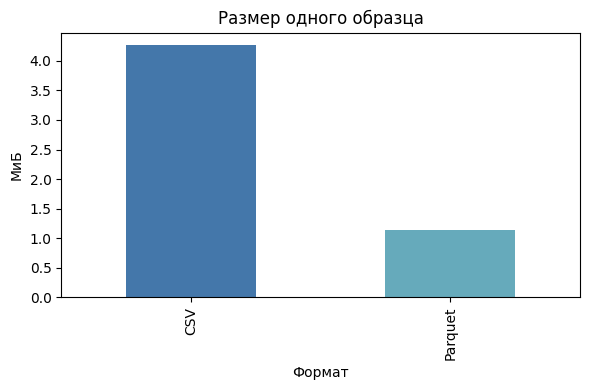

In [18]:
# Шаг 04.18 — Сопоставить размер и время
formats = pd.DataFrame({
    'размер_МиБ': [csv_file.stat().st_size / 2**20, parquet_file.stat().st_size / 2**20],
    'запись_с': [csv_write_s, parquet_write_s],
    'чтение_с': [csv_read_s, parquet_read_s],
}, index=['CSV', 'Parquet'])
display(formats)
fig, ax = plt.subplots(figsize=(6, 4))
formats['размер_МиБ'].plot.bar(ax=ax, color=['#4477aa', '#66aabb'])
ax.set(title='Размер одного образца', xlabel='Формат', ylabel='МиБ')
fig.tight_layout()
fig.savefig(plot_dir / '04_форматы.png', dpi=130)
plt.show()
plt.close(fig)

Один замер на одной машине описывает только эту пробу; выбор формата зависит также от совместимости и схемы.

## Проверенный конвейер

Отдельная функция объединяет проверку входа, диагностический журнал и ограничение хранения собственных логов.

**Определить конвейер чанков**

Итоговая функция читает исходный CSV порциями с явными типами и проверяет обязательные значения: дату, положительное количество и неотрицательную цену, согласованность amount с произведением qty и price, допустимый статус. Каждая часть агрегируется по городу и статусу, затем частичные группы объединяются. В конвейере qty и price читаются как int64, чтобы узкий тип не переполнился до проверки неизвестного входа. Дата каждой порции повторно преобразуется с явным форматом и errors=coerce: одного parse_dates недостаточно, поскольку при плохом значении столбец может остаться текстовым. Следующая проверка пропусков обнаружит такой NaT. Диагностический журнал сообщает начало, номер и размер порции, итог и ошибку со стеком при сбое. Логи лежат только в собственной папке _generated/04/logs; при старте удаляются лишь собственные файлы pipeline старше 30 дней. Это достаточная наблюдаемость для важного конвейера без шумных записей из тривиальных функций. Исходный orders.csv функция не изменяет.

In [19]:
# Шаг 04.19 — Определить конвейер чанков
def run_chunk_pipeline(source, target_dir, chunksize=25_000):
    target_dir.mkdir(parents=True, exist_ok=True)
    log_dir = target_dir / 'logs'
    log_dir.mkdir(exist_ok=True)
    cutoff = datetime.now() - timedelta(days=30)
    for old in log_dir.glob('pipeline_*.log'):
        if old.is_file() and datetime.fromtimestamp(old.stat().st_mtime) < cutoff:
            old.unlink()
    log_file = log_dir / f'pipeline_{datetime.now():%Y%m%d_%H%M%S}.log'
    logger = logging.getLogger('orders_pipeline_04')
    logger.setLevel(logging.INFO)
    logger.propagate = False
    for old_handler in logger.handlers[:]:
        logger.removeHandler(old_handler)
        old_handler.close()
    handler = logging.FileHandler(log_file, encoding='utf-8')
    handler.setFormatter(logging.Formatter('%(asctime)s %(levelname)s %(message)s'))
    logger.addHandler(handler)
    partials = []
    rows = 0
    try:
        logger.info('Старт: файл=%s, размер_порции=%s', source, chunksize)
        reader = pd.read_csv(
            source,
            usecols=['order_id', 'order_ts', 'city', 'status', 'qty', 'price', 'amount'],
            dtype={'order_id': 'int64', 'city': 'string', 'status': 'string',
                   'qty': 'int64', 'price': 'int64', 'amount': 'int64'},
            parse_dates=['order_ts'], chunksize=chunksize)
        for number, piece in enumerate(reader, 1):
            piece['order_ts'] = pd.to_datetime(
                piece['order_ts'], format='%Y-%m-%d %H:%M:%S', errors='coerce')
            if piece.isna().any().any():
                raise ValueError(f'Пропуски в порции {number}')
            if not piece['status'].isin({'delivered', 'cancelled', 'returned', 'in_transit'}).all():
                raise ValueError(f'Неизвестный статус в порции {number}')
            if (piece['qty'] <= 0).any() or (piece['price'] < 0).any():
                raise ValueError(f'Некорректная цена или количество в порции {number}')
            correct_amount = piece['qty'].astype('int64') * piece['price'].astype('int64')
            if not piece['amount'].eq(correct_amount).all():
                raise ValueError(f'Неверная сумма в порции {number}')
            part = piece.groupby(['city', 'status'], as_index=False).agg(
                amount_sum=('amount', 'sum'), order_count=('order_id', 'size'))
            partials.append(part)
            rows += len(piece)
            logger.info('Порция %s: строк=%s, накоплено=%s, групп=%s',
                        number, len(piece), rows, len(part))
        if not partials:
            raise ValueError('Пустой входной файл')
        result = pd.concat(partials, ignore_index=True).groupby(
            ['city', 'status'], as_index=False).agg(
                amount_sum=('amount_sum', 'sum'), order_count=('order_count', 'sum'))
        result['mean_amount'] = result['amount_sum'] / result['order_count']
        output = target_dir / 'summary.csv'
        result.to_csv(output, index=False)
        logger.info('Готово: строк=%s, групп=%s, сумма=%s, результат=%s',
                    rows, len(result), int(result['amount_sum'].sum()), output)
        return result, rows, log_file, output
    except Exception:
        logger.exception('Конвейер остановлен с ошибкой')
        raise
    finally:
        logger.removeHandler(handler)
        handler.close()

print('Конвейер определён; вход и выход будут проверены следующими шагами.')

Конвейер определён; вход и выход будут проверены следующими шагами.


**Выполнить конвейер**

Функция применяется к исходному CSV, но все новые файлы помещаются в _generated/04. Выводятся число строк, число групп, общая сумма, путь итоговой таблицы и несколько последних строк диагностического журнала. Полный журнал не выводится: для подтверждения достаточно записей о завершении. Если одна порция нарушит условия, функция прервётся и сохранит диагностическое исключение. Здесь лог важен, потому что конвейер выполняет несколько последовательных действий и может остановиться между ними. Повторный запуск создаст новый файл журнала; срок хранения старых собственных записей контролируется на старте.

In [20]:
# Шаг 04.20 — Выполнить конвейер
pipeline_result, pipeline_rows, pipeline_log, pipeline_output = run_chunk_pipeline(
    source, artifact_dir, chunksize=25_000)
print('Обработано строк:', pipeline_rows, 'групп:', len(pipeline_result),
      'сумма:', int(pipeline_result['amount_sum'].sum()))
print('Таблица:', pipeline_output, 'журнал:', pipeline_log)
print(chr(10).join(pipeline_log.read_text(encoding='utf-8').splitlines()[-3:]))
display(pipeline_result.head())

Обработано строк: 200000 групп: 64 сумма: 6266419540
Таблица: C:\Users\user\Downloads\BigData_Kit\course\practice\Модуль 1 Обработка данных в Pandas\_generated\04\summary.csv журнал: C:\Users\user\Downloads\BigData_Kit\course\practice\Модуль 1 Обработка данных в Pandas\_generated\04\logs\pipeline_20261019_014245.log
2026-10-19 01:42:45,604 INFO Порция 7: строк=25000, накоплено=175000, групп=64
2026-10-19 01:42:45,652 INFO Порция 8: строк=25000, накоплено=200000, групп=64
2026-10-19 01:42:45,658 INFO Готово: строк=200000, групп=64, сумма=6266419540, результат=C:\Users\user\Downloads\BigData_Kit\course\practice\Модуль 1 Обработка данных в Pandas\_generated\04\summary.csv


,city,status,amount_sum,order_count,mean_amount
0,Волгоград,cancelled,10711930,367,29187.820163
1,Волгоград,delivered,117797970,3740,31496.783422
2,Волгоград,in_transit,5162520,170,30367.764706
3,Волгоград,returned,7114050,225,31618.000000
4,Воронеж,cancelled,12053530,346,34836.791908


**Сверить полный и частичный расчёт**

Полная таблица независимо группируется по тем же городу и статусу. Обе таблицы сортируются по ключам; pandas assert_frame_equal проверяет целые суммы и количества, а np.allclose — средние, вычисленные как отношение. Дополнительно проверяются число строк и общая сумма. Точное равенство целых денежных сумм необходимо: допуск для float здесь скрыл бы ошибку. Эта сверка подтверждает работу конвейера именно на данном файле и не заменяет валидацию каждого будущего источника. Важен также смысл групп: частичные результаты с одинаковыми ключами были объединены после чтения всех порций.

In [21]:
# Шаг 04.21 — Сверить полный и частичный расчёт
full_groups = typed.groupby(['city', 'status'], as_index=False).agg(
    amount_sum=('amount', 'sum'), order_count=('amount', 'size'))
full_groups['mean_amount'] = full_groups['amount_sum'] / full_groups['order_count']
keys = ['city', 'status']
left = pipeline_result.sort_values(keys).reset_index(drop=True)
right = full_groups.sort_values(keys).reset_index(drop=True)
pd.testing.assert_frame_equal(left[keys + ['amount_sum', 'order_count']],
                              right[keys + ['amount_sum', 'order_count']], check_dtype=False)
assert np.allclose(left['mean_amount'], right['mean_amount'])
assert pipeline_rows == len(typed)
assert int(left['amount_sum'].sum()) == full_sum
print('Группы, количество и целые суммы совпали; средние совпали с допуском для float.')

Группы, количество и целые суммы совпали; средние совпали с допуском для float.


**Решить задачу о среднем чеке статусов**

Из результата конвейера можно получить средний чек по статусу, но нельзя усреднить средние городов: размеры городских групп отличаются. amount_sum и order_count повторно складываются по статусу, затем итоговые величины делятся друг на друга. Затем выполняется сравнение с результатом полного DataFrame. Эта задача закрепляет двухуровневое агрегирование: сначала порции, затем города и статусы, затем ещё один требуемый уровень. Разные уровни допустимы, если сохранены аддитивные достаточные статистики. Задача имеет уже выполненное решение. Значение по статусу не следует читать как средний чек отдельного человека: единицей остаётся заказ.

In [22]:
# Шаг 04.22 — Решить задачу о среднем чеке статусов
status_from_pipeline = pipeline_result.groupby('status', as_index=False).agg(
    amount_sum=('amount_sum', 'sum'), order_count=('order_count', 'sum'))
status_from_pipeline['mean_amount'] = (
    status_from_pipeline['amount_sum'] / status_from_pipeline['order_count'])
status_full_mean = typed.groupby('status')['amount'].mean().sort_index()
assert np.allclose(status_from_pipeline.set_index('status')['mean_amount'].sort_index(),
                   status_full_mean)
display(status_from_pipeline.sort_values('mean_amount', ascending=False))

,status,amount_sum,order_count,mean_amount
3,returned,318262720,10045,31683.695371
0,cancelled,565172220,17980,31433.382647
1,delivered,5135476730,164061,31302.239594
2,in_transit,247507870,7914,31274.686631


**Решить задачу о доставленных заказах городов**

Последняя задача выбирает доставленные заказы и сравнивает города по общей сумме и количеству. Оба показателя уже присутствуют в результате конвейера, поэтому исходный CSV повторно читать не нужно. Рейтинг выводится рядом со сверкой суммы доставленных заказов с ранее вычисленным контрольным значением. Большая сумма города может возникать из большего числа заказов или большей средней стоимости; рядом выводится mean_amount. Этот результат относится к синтетическому набору и не является оценкой реального рынка. Задача показывает пользу сохранения достаточных статистик: после чанкового прохода можно отвечать на несколько вопросов без удержания всех строк в памяти.

In [23]:
# Шаг 04.23 — Решить задачу о доставленных заказах городов
delivered_city = pipeline_result.loc[pipeline_result['status'].eq('delivered')].copy()
delivered_city = delivered_city.sort_values('amount_sum', ascending=False)
assert int(delivered_city['amount_sum'].sum()) == delivered_sum
display(delivered_city[['city', 'order_count', 'amount_sum', 'mean_amount']].head(10))
print('Доставлено на сумму:', int(delivered_city['amount_sum'].sum()))

,city,order_count,amount_sum,mean_amount
25,Москва,66516,2076257880,31214.412773
33,Новосибирск,17846,582032610,32614.177407
53,Санкт-Петербург,15918,509258020,31992.588265
13,Казань,6317,198400470,31407.388001
49,Самара,6067,192444940,31719.950552
9,Екатеринбург,6195,190660510,30776.514931
21,Красноярск,5881,185672890,31571.652780
17,Краснодар,5834,177962450,30504.362359
57,Тюмень,5636,176485110,31313.894606
45,Ростов-на-Дону,4719,143674010,30445.859292


Доставлено на сумму: 5135476730


Сверка с полным чтением подтверждает арифметику итогов на данном файле. Граница со Spark — размер, распределение и эксплуатационные требования.

На этих 200 000 строках Pandas позволил уменьшить память и пройти CSV порциями, сохранив точные денежные суммы. Следующий шаг к Spark возникает, когда данные, параллельное выполнение или эксплуатационные требования превосходят удобные пределы одной машины; переносится логика схемы, проверки входа и аддитивных агрегатов. Распределённые механизмы Spark будут изучаться отдельно, здесь лишь обозначена граница применения.